## Problem Statement 1: Wine Quality Prediction (Supervised Learning)

### Context
'GrapeVine Estates' is a prominent wine manufacturing company. Traditionally, their wine quality is assessed by human wine-tasters at the end of the production cycle. This manual process is time-consuming, expensive, and subject to human bias. The Quality Control department wants to modernize this workflow by predicting the quality of the wine immediately after the laboratory chemical tests are concluded. You, as a data scientist, are tasked with building a predictive model to automate this quality assessment.

### Objective
To build a supervised machine learning model that predicts the 'Quality Score' (from 0 to 10) of a wine based solely on its physicochemical test results, thereby reducing reliance on human tasting and speeding up the production pipeline.

**Key questions to be answered**

- Which physicochemical properties (e.g., alcohol, volatile acidity) are the strongest predictors of wine quality?
- Does a higher concentration of residual sugar or alcohol guarantee a higher quality rating?   
- Can we accurately classify a wine as "Good" (quality $\ge$ 7) or "Bad" (quality $<$ 7) using only chemical thresholds?   

### Data Description   
- fixed acidity: Most acids involved with wine or fixed or nonvolatile (do not evaporate readily).   
- volatile acidity: The amount of acetic acid in wine, which at too high of levels can lead to an unpleasant, vinegar taste.   
- citric acid: Found in small quantities, citric acid can add 'freshness' and flavor to wines.   
- residual sugar: The amount of sugar remaining after fermentation stops.
- chlorides: The amount of salt in the wine.
- free sulfur dioxide: The free form of SO2 exists in equilibrium between molecular SO2 (as a dissolved gas) and bisulfite ion.
- total sulfur dioxide: Amount of free and bound forms of SO2.
- density: The density of wine is close to that of water depending on the percent alcohol and sugar content.
- pH: Describes how acidic or basic a wine is on a scale from 0 (very acidic) to 14 (very basic).
- sulphates: A wine additive which can contribute to sulfur dioxide gas (SO2) levels.
- alcohol: The percent alcohol content of the wine.
- quality: Output variable (based on sensory data, score between 0 and 10).

### Domain Information
- Supervised Learning: Machine learning where the model is trained on labeled data (here, the quality column is the label).
- Sensory Assessment: The traditional method of judging wine using human senses (taste, smell, and sight).
- Physicochemical Tests: Objective laboratory tests that measure the exact chemical makeup of a substance.

## 1. Import Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load Dataset


In [ ]:

df = pd.read_csv("/content/winequality.csv", sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Understand the Dataset


In [ ]:
print("Shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape: (1599, 12)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values:
fixed acidity           0
volatile acidity        0
citric acid       

## 4. Check Duplicate Rows


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 240
Shape after removing duplicates: (1359, 12)


In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

## 5. Data Visualization

### Wine Quality Count

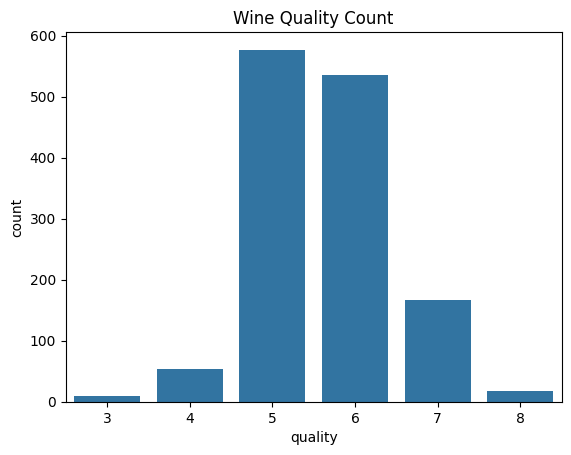

In [ ]:
sns.countplot(data=df, x='quality')
plt.title('Wine Quality Count')
plt.show()

## Correlation Heatmap



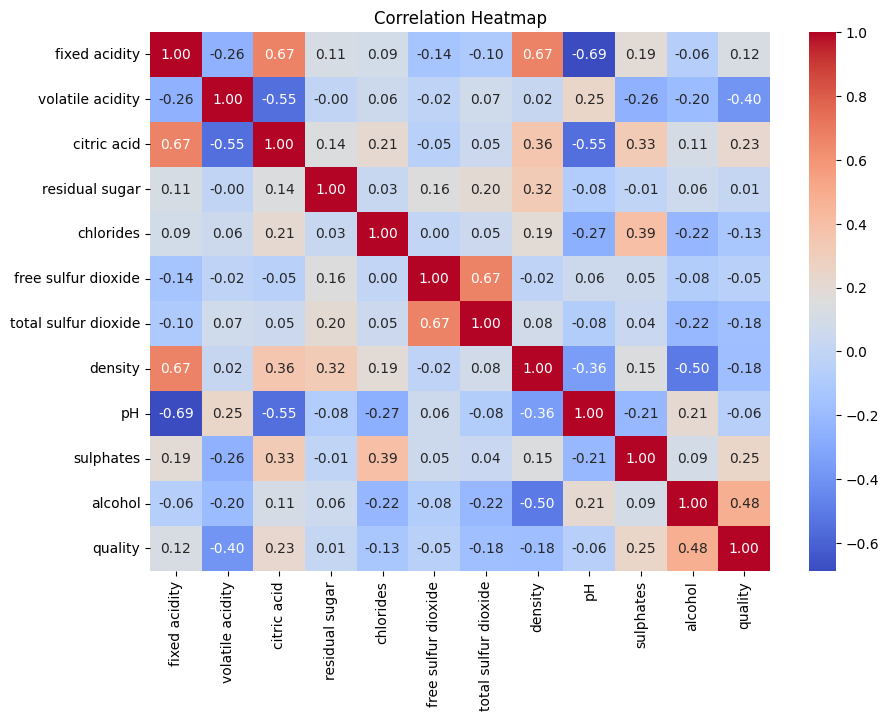

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### Alcohol and Quality


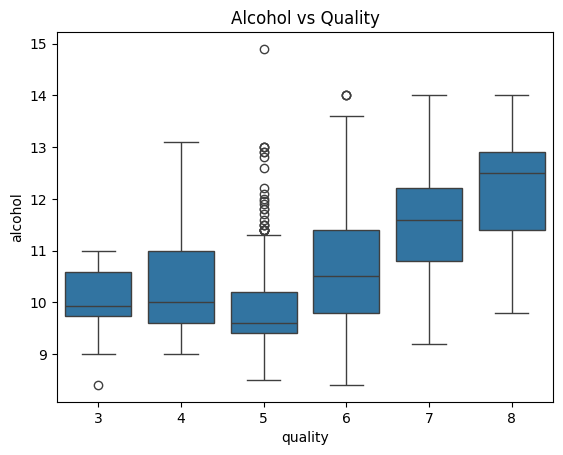

In [ ]:
sns.boxplot(data=df, x='quality', y='alcohol')
plt.title('Alcohol vs Quality')
plt.show()

### Volatile Acidity and Quality

This chart compares volatile acidity across wine quality scores.

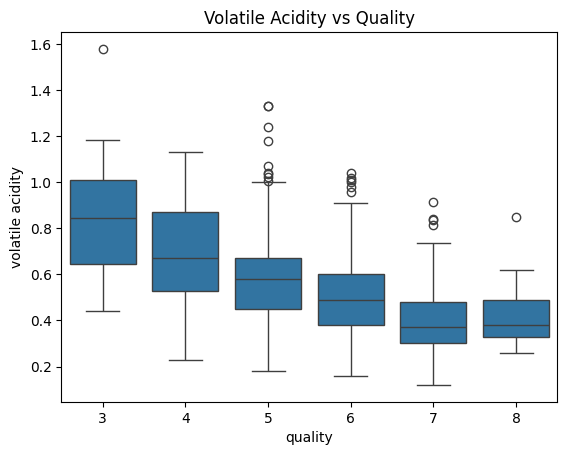

In [ ]:
sns.boxplot(data=df, x='quality', y='volatile acidity')
plt.title('Volatile Acidity vs Quality')
plt.show()

## 6. Prepare the Data

Create a new column called `premium`.

- 1 means premium wine (quality 7 or more)
- 0 means not premium wine (quality below 7)

In [ ]:
df['premium'] = (df['quality'] >= 7).astype(int)

print(df['premium'].value_counts())

premium
0    1175
1     184
Name: count, dtype: int64


### Separate Features and Target

`X` contains the chemical properties. `y` contains the answer we want the model to predict.

We remove `quality` because we are predicting the premium label using the other columns.

In [ ]:
X = df.drop(['quality', 'premium'], axis=1)
y = df['premium']

### Split the Dataset

Use 80% of the data for training and 20% for testing.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1087, 11)
Testing data: (272, 11)


## 7. Train Machine Learning Models

We will use two ensemble models:

1. **Random Forest:** Uses many decision trees and combines their results.
2. **Gradient Boosting:** Builds trees one after another to improve predictions.

In [ ]:
model1 = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

model2 = GradientBoostingClassifier(random_state=42)

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


## 8. Check Model Accuracy

Now use the test data to make predictions and compare the accuracy of both models.

In [ ]:
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

accuracy1 = accuracy_score(y_test, pred1)
accuracy2 = accuracy_score(y_test, pred2)

print("Random Forest Accuracy:", accuracy1)
print("Gradient Boosting Accuracy:", accuracy2)

Random Forest Accuracy: 0.8860294117647058
Gradient Boosting Accuracy: 0.8713235294117647


### Compare the Models

The bar chart compares the accuracy of the two models. Accuracy alone is not enough when the classes are imbalanced, so we will also check the classification report.

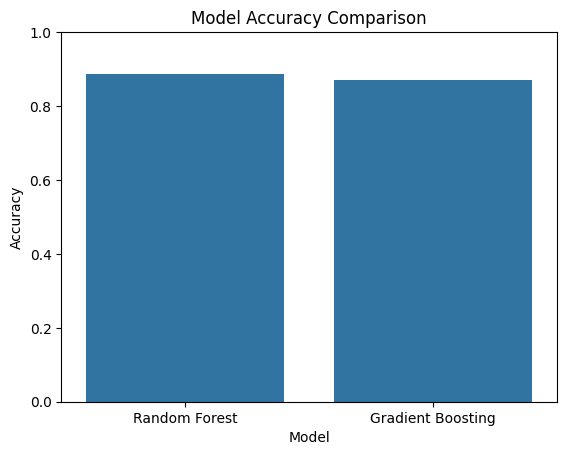

In [ ]:
accuracy = pd.DataFrame({
    'Model': ['Random Forest', 'Gradient Boosting'],
    'Accuracy': [accuracy1, accuracy2]
})

sns.barplot(data=accuracy, x='Model', y='Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()

## 9. Classification Report

Precision, Recall and F1-score help us understand how well the model identifies premium wines.

Recall is important because we want to find as many actual premium wines as possible.

In [ ]:
print("Random Forest Results:")
print(classification_report(y_test, pred1, zero_division=0))

print("Gradient Boosting Results:")
print(classification_report(y_test, pred2, zero_division=0))

Random Forest Results:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       235
           1       0.69      0.30      0.42        37

    accuracy                           0.89       272
   macro avg       0.79      0.64      0.68       272
weighted avg       0.87      0.89      0.87       272

Gradient Boosting Results:
              precision    recall  f1-score   support

           0       0.90      0.95      0.93       235
           1       0.54      0.35      0.43        37

    accuracy                           0.87       272
   macro avg       0.72      0.65      0.68       272
weighted avg       0.85      0.87      0.86       272



## 10. Confusion Matrix

The confusion matrix shows correct and incorrect predictions made by the Random Forest model.

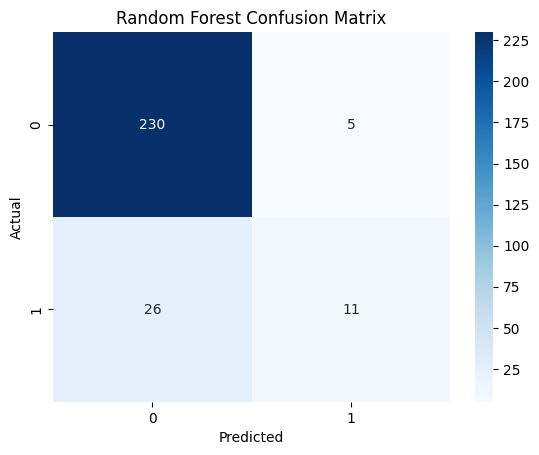

In [ ]:
cm = confusion_matrix(y_test, pred1)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

## 11. Feature Importance

This chart shows which chemical properties were most useful to the Random Forest model.

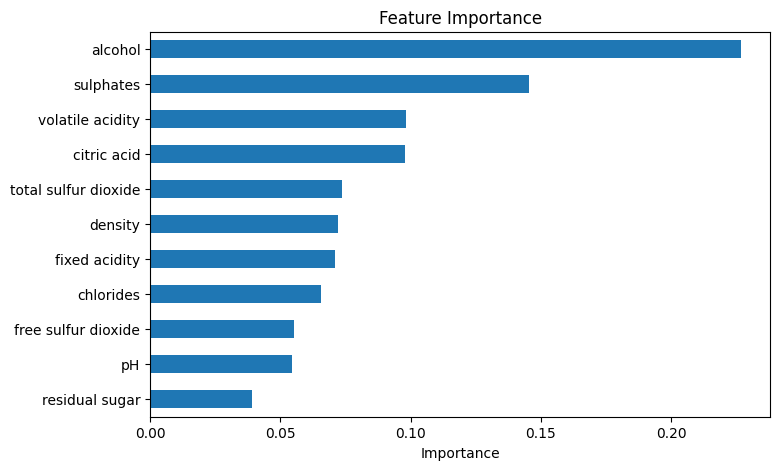

In [ ]:
importance = pd.Series(model1.feature_importances_, index=X.columns)
importance = importance.sort_values()

importance.plot(kind='barh', figsize=(8, 5))
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.show()

## 12. Predict a Wine

Use one example from the test dataset and ask the model to predict whether it is premium.

In [ ]:
sample = X_test.iloc[[0]]

prediction = model1.predict(sample)

if prediction[0] == 1:
    print("This wine is predicted as Premium.")
else:
    print("This wine is predicted as Not Premium.")

This wine is predicted as Not Premium.


## 13. Conclusion

In this project, we used wine chemical properties to predict whether a wine is premium or not.

We performed basic data cleaning and visualization, prepared the data, and trained two ensemble machine learning models: Random Forest and Gradient Boosting.

We compared their accuracy and checked Precision, Recall, F1-score and the confusion matrix. These metrics help us understand how well the models identify premium wines.

The model can help Moonshine identify wines that may need further quality checking. However, it should support expert testing and should not completely replace wine tasting.

**Note:** Premium wine is defined as quality score 7 or above for this project. The model's results depend on the dataset and train-test split.